In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Load the Iris dataset
iris = load_iris(as_frame=True)

X = iris.data
y = iris.target

# Explore the dataset
print("Dataset shape:", X.shape)
print("\nFeature names:")
print(X.columns.tolist())

print("\nTarget classes:")
print(iris.target_names)

print("\nFirst five rows:")
print(X.head())

print("\nClass distribution:")
print(y.value_counts().sort_index())


Dataset shape: (150, 4)

Feature names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Target classes:
['setosa' 'versicolor' 'virginica']

First five rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Class distribution:
target
0    50
1    50
2    50
Name: count, dtype: int64


In [2]:

# Split the data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Check the resulting shapes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())


Training features: (120, 4)
Testing features: (30, 4)
Training labels: (120,)
Testing labels: (30,)

Training class distribution:
target
0    40
1    40
2    40
Name: count, dtype: int64

Testing class distribution:
target
0    10
1    10
2    10
Name: count, dtype: int64


In [3]:

# Create the Random Forest classifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

# Predict on the test set
y_pred = rf_model.predict(X_test)

# Display predictions and actual labels
print("\nFirst 10 predictions:", y_pred[:10])
print("First 10 actual labels:", y_test.iloc[:10].values)


Random Forest model trained successfully!

First 10 predictions: [0 2 1 1 0 1 0 0 2 1]
First 10 actual labels: [0 2 1 1 0 1 0 0 2 1]


In [4]:

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Random Forest Evaluation")
print("------------------------")
print(f"Accuracy: {accuracy:.4f}")

# Detailed classification report
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names
    )
)

# Generate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)


Random Forest Evaluation
------------------------
Accuracy: 0.9000

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30


Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  2  8]]


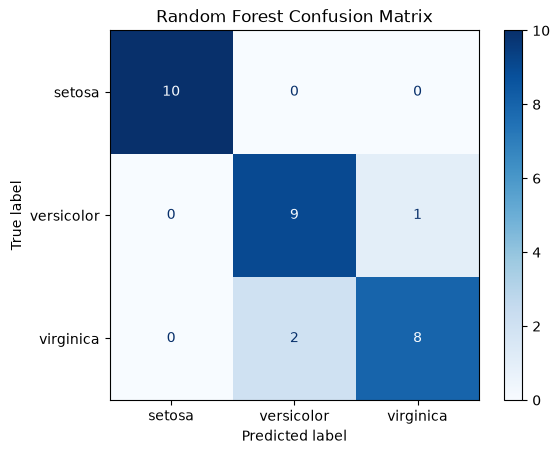

In [5]:

# Visualize the confusion matrix

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Random Forest Confusion Matrix")
plt.show()


Random Forest Feature Importance:
          Feature  Importance
 petal width (cm)    0.437185
petal length (cm)    0.431466
sepal length (cm)    0.116349
 sepal width (cm)    0.015000


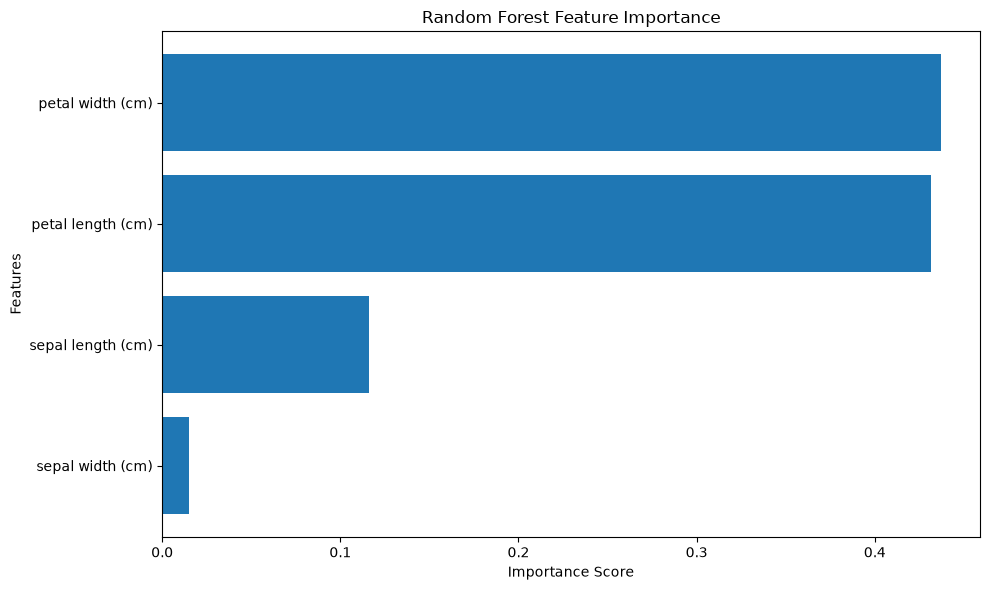

In [6]:

# Extract feature importance
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

# Sort from most important to least important
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Random Forest Feature Importance:")
print(feature_importance.to_string(index=False))

# Visualize feature importance
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [7]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Define the parameter combinations to test
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 3, 5],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

# Use stratified 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Create GridSearchCV
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1
)

# Fit using training data only
grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest mean cross-validation accuracy:")
print(round(grid_search.best_score_, 4))


Best parameters:
{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 200}

Best mean cross-validation accuracy:
0.9667


Tuned Random Forest Evaluation
-------------------------------
Accuracy: 0.9667

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



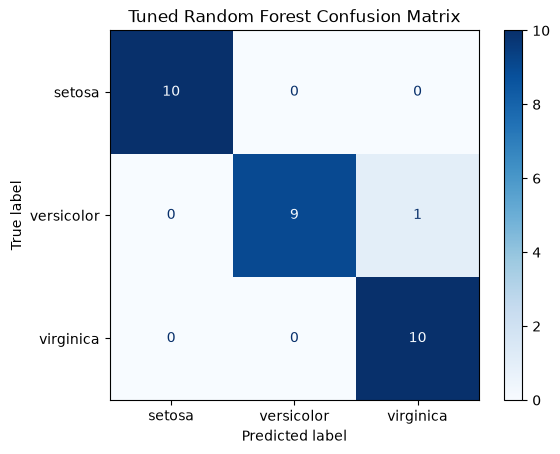

In [8]:

# Get the best model from GridSearchCV
best_rf_model = grid_search.best_estimator_

# Predict on the test set
y_tuned_pred = best_rf_model.predict(X_test)

# Evaluate the tuned model
tuned_accuracy = accuracy_score(y_test, y_tuned_pred)

print("Tuned Random Forest Evaluation")
print("-------------------------------")
print(f"Accuracy: {tuned_accuracy:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_tuned_pred,
        target_names=iris.target_names
    )
)

# Display the confusion matrix
tuned_cm = confusion_matrix(y_test, y_tuned_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=tuned_cm,
    display_labels=iris.target_names
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Tuned Random Forest Confusion Matrix")
plt.show()


In [10]:

from sklearn.metrics import f1_score

# Compare the original and tuned Random Forest models

rf_comparison = pd.DataFrame({
    "Model": [
        "Original Random Forest",
        "Tuned Random Forest"
    ],
    "Test Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_tuned_pred)
    ],
    "Weighted F1-Score": [
        f1_score(y_test, y_pred, average="weighted"),
        f1_score(y_test, y_tuned_pred, average="weighted")
    ]
})

print(rf_comparison.to_string(index=False))

# Save the comparison results
rf_comparison.to_csv(
    "random_forest_model_comparison.csv",
    index=False
)

print("\nModel comparison saved successfully!")


                 Model  Test Accuracy  Weighted F1-Score
Original Random Forest       0.900000           0.899749
   Tuned Random Forest       0.966667           0.966583

Model comparison saved successfully!


In [11]:

import joblib

# Save the tuned Random Forest model
joblib.dump(
    best_rf_model,
    "tuned_random_forest_iris.pkl"
)

print("Tuned Random Forest model saved successfully!")
print("Filename: tuned_random_forest_iris.pkl")


Tuned Random Forest model saved successfully!
Filename: tuned_random_forest_iris.pkl
